# Indian License Plate Detection and Recognition — Inference

**PP-OCRv4 vs PP-OCRv5 | Lynkit Computer Vision Assessment**

Run in Google Colab with GPU. Upload `PaddleOCR_Indian_Plates_Backup.zip` and the original Kaggle `archive.zip` when prompted. The notebook retains outputs from the completed run; Colab runtime paths are ephemeral. The detector requires a separately trained YOLO checkpoint at `/content/license_plate_detection/yolo11n_indian_plates/weights/best.pt`. The checkpoint was generated during the original run but is **not embedded in this notebook**. If absent, train the detector from the XML-to-YOLO dataset using the optional training cell below.

**Compatibility:** This run used a subprocess with `LD_PRELOAD=/usr/lib/x86_64-linux-gnu/libnccl.so.2` to resolve a CUDA/NCCL conflict affecting PyTorch. This path is environment-specific.

In [ ]:
import os
import sys
import platform

print("Python version:", platform.python_version())
print("Working directory:", os.getcwd())

try:
    import paddle
    print("PaddlePaddle version:", paddle.__version__)
    print("GPU available:", paddle.is_compiled_with_cuda())
    print("Current device:", paddle.device.get_device())
except ImportError:
    print("PaddlePaddle is not installed in this runtime.")

print("PaddleOCR repository exists:", os.path.isdir("/content/PaddleOCR"))
print("PP-OCRv4 checkpoint exists:",
      os.path.isfile("/content/output/PP-OCRv4/best_accuracy.pdparams"))
print("PP-OCRv5 checkpoint exists:",
      os.path.isfile("/content/output/PP-OCRv5/best_accuracy.pdparams"))

Python version: 3.13.16
Working directory: /content
PaddlePaddle is not installed in this runtime.
PaddleOCR repository exists: False
PP-OCRv4 checkpoint exists: False
PP-OCRv5 checkpoint exists: False


In [ ]:
from google.colab import files
import os
import zipfile

print("Select PaddleOCR_Indian_Plates_Backup.zip from your laptop.")

uploaded = files.upload()

for filename in uploaded:
    print("Uploaded:", filename)

    with zipfile.ZipFile(filename, "r") as zip_ref:
        zip_ref.extractall("/content/indian_plate_backup")

print("\nBackup extracted successfully!")

backup_dir = "/content/indian_plate_backup"

for root, dirs, filenames in os.walk(backup_dir):
    for name in filenames:
        if name.endswith(".pdparams"):
            path = os.path.join(root, name)
            print("Model found:", path)
            print("Size:", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

Select PaddleOCR_Indian_Plates_Backup.zip from your laptop.


Saving PaddleOCR_Indian_Plates_Backup.zip to PaddleOCR_Indian_Plates_Backup.zip
Uploaded: PaddleOCR_Indian_Plates_Backup.zip

Backup extracted successfully!
Model found: /content/indian_plate_backup/models/PP-OCRv5_best_accuracy.pdparams
Size: 65.46 MB
Model found: /content/indian_plate_backup/models/PP-OCRv4_best_accuracy.pdparams
Size: 65.46 MB


In [ ]:
# Check the GPU assigned to this Colab runtime
!nvidia-smi

# Install PaddlePaddle GPU
!pip install -q paddlepaddle-gpu==3.3.0

# Clone PaddleOCR repository
!git clone -q https://github.com/PaddlePaddle/PaddleOCR.git /content/PaddleOCR

# Install PaddleOCR dependencies
%cd /content/PaddleOCR
!pip install -q -r requirements.txt

Tue Oct 27 09:02:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Install PaddlePaddle GPU from the official PaddlePaddle package index
!python -m pip install paddlepaddle-gpu==3.3.0 -i https://www.paddlepaddle.org.cn/packages/stable/cu129/

Looking in indexes: https://www.paddlepaddle.org.cn/packages/stable/cu129/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 GB 5.1 MB/s  0:02:41
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.6/89.6 MB 18.4 MB/s  0:00:04
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 40.0 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 21.1 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 781.4/781.4 MB 10.8 MB/s  0:00:47
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 580.7/580.7 MB 13.1 MB/s  0:00:34
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.9/200.9 MB 20.1 MB/s  0:00:10
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.8/331.8 MB 20.1 MB/s  0:00:16
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.4/366.4 MB 20.2 MB/s  0:00:17
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.2/287.2 MB 20.2 MB/s  0:00:14
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 MB 18.5 MB/s  0:00:16
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.7/39.7 MB

In [ ]:
import paddle

print("PaddlePaddle version:", paddle.__version__)
print("GPU support:", paddle.is_compiled_with_cuda())
print("Current device:", paddle.device.get_device())

# Test an actual GPU computation
paddle.set_device("gpu")
x = paddle.randn([100, 100])
y = paddle.matmul(x, x)

print("GPU computation successful:", y.shape)
print("Tensor device:", y.place)

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


PaddlePaddle version: 3.3.0
GPU support: True
Current device: gpu:0
GPU computation successful: paddle.Size([100, 100])
Tensor device: Place(gpu:0)


In [ ]:
import os
import shutil
import subprocess
import yaml

repo_dir = "/content/PaddleOCR"
backup_dir = "/content/indian_plate_backup"

# Clone PaddleOCR if not already present
if not os.path.isdir(os.path.join(repo_dir, "ppocr")):
    subprocess.run(
        ["git", "clone", "-q",
         "https://github.com/PaddlePaddle/PaddleOCR.git",
         repo_dir],
        check=True
    )

# Restore custom character dictionary
dict_source = os.path.join(backup_dir, "indian_plate_dict.txt")
dict_target = os.path.join(
    repo_dir, "ppocr/utils/indian_plate_dict.txt"
)
shutil.copy2(dict_source, dict_target)

# Restore model configurations
config_dir = "/content/indian_plate_configs"
os.makedirs(config_dir, exist_ok=True)

for model in ["PP-OCRv4", "PP-OCRv5"]:
    source = os.path.join(
        backup_dir, "configs", f"{model}_indian_plate.yml"
    )
    target = os.path.join(
        config_dir, f"{model}_indian_plate.yml"
    )

    shutil.copy2(source, target)

    with open(target, "r") as f:
        config = yaml.safe_load(f)

    # Point the config to the restored checkpoint
    config["Global"]["checkpoints"] = os.path.join(
        backup_dir, "models", f"{model}_best_accuracy.pdparams"
    )
    config["Global"]["character_dict_path"] = dict_target

    with open(target, "w") as f:
        yaml.safe_dump(config, f, sort_keys=False)

    print(model, "configuration restored")

print("\nDictionary exists:", os.path.isfile(dict_target))
print("PaddleOCR repository exists:", os.path.isdir(repo_dir))
print("Dictionary characters:", len(open(dict_target).read().splitlines()))

PP-OCRv4 configuration restored
PP-OCRv5 configuration restored

Dictionary exists: True
PaddleOCR repository exists: True
Dictionary characters: 36


In [ ]:
%cd /content/PaddleOCR

# Install dependencies required by the PaddleOCR repository
!python -m pip install -r requirements.txt

/content/PaddleOCR
Ignoring lmdb: markers 'python_version < "3.9"' don't match your environment


In [ ]:
import os
import sys

sys.path.insert(0, "/content/PaddleOCR")

from ppocr.modeling.architectures import build_model
from ppocr.utils.save_load import load_model

print("PaddleOCR imports: SUCCESS")

for model in ["PP-OCRv4", "PP-OCRv5"]:
    config_path = f"/content/indian_plate_configs/{model}_indian_plate.yml"
    checkpoint_path = (
        f"/content/indian_plate_backup/models/"
        f"{model}_best_accuracy.pdparams"
    )

    print(f"{model} config exists:", os.path.isfile(config_path))
    print(f"{model} checkpoint exists:", os.path.isfile(checkpoint_path))

Skipping import of the encryption module.
PaddleOCR imports: SUCCESS
PP-OCRv4 config exists: True
PP-OCRv4 checkpoint exists: True
PP-OCRv5 config exists: True
PP-OCRv5 checkpoint exists: True


In [ ]:
import os
import shutil

backup_dir = "/content/indian_plate_backup"

# Restore cropped license plate images
source_crops = os.path.join(backup_dir, "plate_crops")
target_crops = "/content/plate_crops"

if not os.path.isdir(source_crops):
    raise FileNotFoundError("Plate crops missing from backup!")

shutil.copytree(source_crops, target_crops, dirs_exist_ok=True)

# Restore training and validation labels
dataset_dir = "/content/ocr_dataset"
os.makedirs(dataset_dir, exist_ok=True)

for filename in ["train.txt", "val.txt"]:
    shutil.copy2(
        os.path.join(backup_dir, "labels", filename),
        os.path.join(dataset_dir, filename)
    )

# Verify validation dataset
val_path = os.path.join(dataset_dir, "val.txt")

with open(val_path, "r") as f:
    validation_samples = [
        line.strip().split("\t", 1)
        for line in f if line.strip()
    ]

missing_images = [
    path for path, label in validation_samples
    if not os.path.isfile(path)
]

print("Total validation samples:", len(validation_samples))
print("Missing images:", len(missing_images))
print("Total restored plate crops:", len(os.listdir(target_crops)))

print("\nFirst 3 validation samples:")
for path, label in validation_samples[:3]:
    print(os.path.basename(path), "→", label)


Total validation samples: 330
Missing images: 0
Total restored plate crops: 1695

First 3 validation samples:
video11_1560_0.jpg → MH02BQ9628
video11_1620_0.jpg → MH02BQ9628
video11_3710_0.jpg → MH03AR7140


In [ ]:
import sys
import yaml
import paddle

sys.path.insert(0, "/content/PaddleOCR")

from ppocr.modeling.architectures import build_model
from ppocr.postprocess import build_post_process

paddle.set_device("gpu")

loaded_models = {}
loaded_configs = {}
loaded_postprocess = {}

for model_name in ["PP-OCRv4", "PP-OCRv5"]:

    config_path = (
        f"/content/indian_plate_configs/"
        f"{model_name}_indian_plate.yml"
    )

    checkpoint_path = (
        f"/content/indian_plate_backup/models/"
        f"{model_name}_best_accuracy.pdparams"
    )

    with open(config_path, "r") as f:
        config = yaml.safe_load(f)

    post_process = build_post_process(
        config["PostProcess"],
        config["Global"]
    )

    char_num = len(post_process.character)
    head_config = config["Architecture"]["Head"]

    if head_config["name"] == "MultiHead":
        head_config["out_channels_list"] = {
            "CTCLabelDecode": char_num,
            "SARLabelDecode": char_num + 2,
            "NRTRLabelDecode": char_num + 3
        }
    else:
        head_config["out_channels"] = char_num

    model = build_model(config["Architecture"])

    weights = paddle.load(checkpoint_path)
    model.set_state_dict(weights)
    model.eval()

    loaded_models[model_name] = model
    loaded_configs[model_name] = config
    loaded_postprocess[model_name] = post_process

    print(f"{model_name}: loaded successfully")
    print("Character count:", char_num)

print("\nModels ready:", list(loaded_models.keys()))
print("Device:", paddle.device.get_device())

PP-OCRv4: loaded successfully
Character count: 37
PP-OCRv5: loaded successfully
Character count: 37

Models ready: ['PP-OCRv4', 'PP-OCRv5']
Device: gpu:0


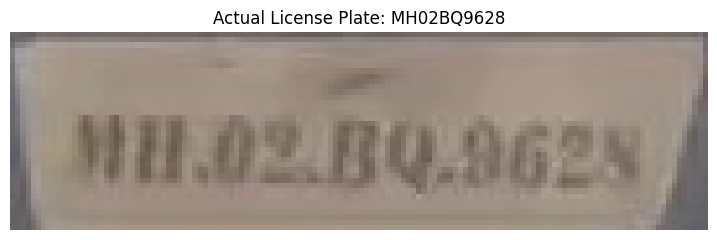

Ground truth: MH02BQ9628
--------------------------------------------------
PP-OCRv4
Predicted: MH02B0362
Confidence: 0.7849
Exact match: False
--------------------------------------------------
PP-OCRv5
Predicted: MH02BQ9628
Confidence: 0.9478
Exact match: True
--------------------------------------------------


In [ ]:
import cv2
import numpy as np
import paddle
import matplotlib.pyplot as plt

# Select the first validation sample
image_path, actual_text = validation_samples[0]

image = cv2.imread(image_path)
if image is None:
    raise ValueError(f"Cannot read image: {image_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(9, 3))
plt.imshow(image_rgb)
plt.title(f"Actual License Plate: {actual_text}")
plt.axis("off")
plt.show()

print("Ground truth:", actual_text)
print("-" * 50)

for model_name in ["PP-OCRv4", "PP-OCRv5"]:

    config = loaded_configs[model_name]
    model = loaded_models[model_name]
    post_process = loaded_postprocess[model_name]

    # Apply the validation image preprocessing pipeline
    from ppocr.data.imaug import create_operators, transform

    transforms = config["Eval"]["dataset"]["transforms"]
    operators = create_operators(transforms, config["Global"])

    data = {
        "image": open(image_path, "rb").read(),
        "label": actual_text
    }

    processed = transform(data, operators)

    if processed is None:
        raise ValueError(f"Preprocessing failed for {model_name}")

    image_tensor = np.expand_dims(processed[0], axis=0)
    image_tensor = paddle.to_tensor(image_tensor)

    with paddle.no_grad():
        prediction = model(image_tensor)

    result = post_process(prediction)

    predicted_text, confidence = result[0]

    print(f"{model_name}")
    print("Predicted:", predicted_text)
    print("Confidence:", round(float(confidence), 4))
    print("Exact match:", predicted_text == actual_text)
    print("-" * 50)

In [ ]:
import time
import pandas as pd
import numpy as np
import paddle

from ppocr.data.imaug import create_operators, transform

results = []

for model_name in ["PP-OCRv4", "PP-OCRv5"]:

    model = loaded_models[model_name]
    config = loaded_configs[model_name]
    post_process = loaded_postprocess[model_name]

    operators = create_operators(
        config["Eval"]["dataset"]["transforms"],
        config["Global"]
    )

    correct = 0
    processed_count = 0
    start_time = time.perf_counter()

    for image_path, actual_text in validation_samples:

        with open(image_path, "rb") as f:
            image_bytes = f.read()

        data = {
            "image": image_bytes,
            "label": actual_text
        }

        processed = transform(data, operators)

        if processed is None:
            continue

        image_tensor = paddle.to_tensor(
            np.expand_dims(processed[0], axis=0)
        )

        with paddle.no_grad():
            prediction = model(image_tensor)
            decoded = post_process(prediction)

        predicted_text, confidence = decoded[0]
        is_correct = predicted_text == actual_text

        correct += int(is_correct)
        processed_count += 1

        results.append({
            "Model": model_name,
            "Image": image_path,
            "Actual": actual_text,
            "Predicted": predicted_text,
            "Confidence": float(confidence),
            "Correct": is_correct
        })

    paddle.device.cuda.synchronize()
    elapsed = time.perf_counter() - start_time

    print(f"\n{model_name}")
    print("Samples evaluated:", processed_count)
    print("Correct predictions:", correct)
    print("Exact-match accuracy:",
          f"{100 * correct / processed_count:.2f}%")
    print("Total inference time:", f"{elapsed:.2f} seconds")

results_df = pd.DataFrame(results)

results_df.to_csv(
    "/content/license_plate_batch_results.csv",
    index=False
)

print("\nBatch results saved successfully.")


PP-OCRv4
Samples evaluated: 330
Correct predictions: 187
Exact-match accuracy: 56.67%
Total inference time: 12.18 seconds

PP-OCRv5
Samples evaluated: 330
Correct predictions: 271
Exact-match accuracy: 82.12%
Total inference time: 12.31 seconds

Batch results saved successfully.


PP-OCRv4 incorrect predictions: 143
PP-OCRv5 incorrect predictions: 59


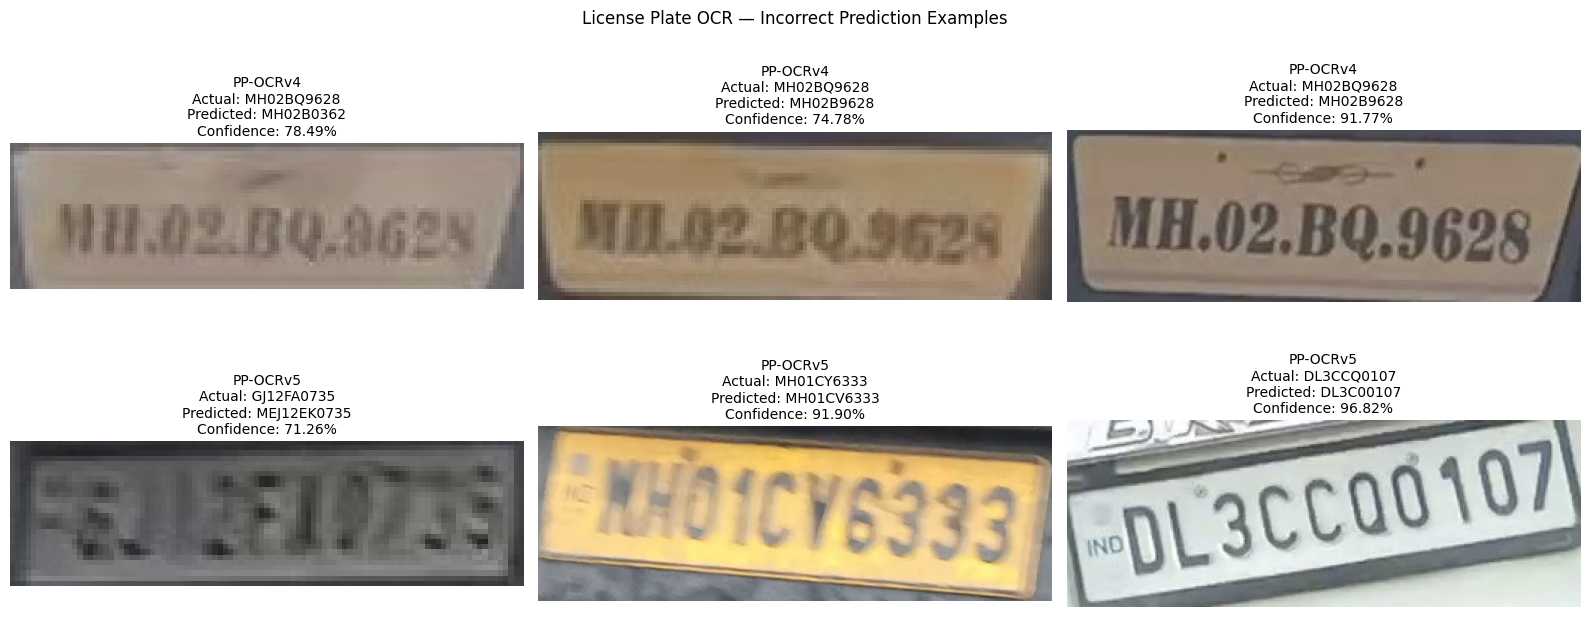

In [ ]:
import matplotlib.pyplot as plt
import cv2
import pandas as pd

# Incorrect predictions from each model
errors_v4 = results_df[
    (results_df["Model"] == "PP-OCRv4") &
    (~results_df["Correct"])
]

errors_v5 = results_df[
    (results_df["Model"] == "PP-OCRv5") &
    (~results_df["Correct"])
]

print("PP-OCRv4 incorrect predictions:", len(errors_v4))
print("PP-OCRv5 incorrect predictions:", len(errors_v5))

fig, axes = plt.subplots(2, 3, figsize=(16, 7))

for row_index, (model_name, errors) in enumerate([
    ("PP-OCRv4", errors_v4),
    ("PP-OCRv5", errors_v5)
]):
    for col_index, (_, sample) in enumerate(errors.head(3).iterrows()):
        image = cv2.imread(sample["Image"])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        ax = axes[row_index, col_index]
        ax.imshow(image)
        ax.set_title(
            f"{model_name}\n"
            f"Actual: {sample['Actual']}\n"
            f"Predicted: {sample['Predicted']}\n"
            f"Confidence: {sample['Confidence']:.2%}",
            fontsize=10
        )
        ax.axis("off")

plt.suptitle("License Plate OCR — Incorrect Prediction Examples")
plt.tight_layout()
plt.savefig(
    "/content/ocr_incorrect_predictions.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

Confidence Summary:


,Model,Correct,count,mean,median,min,max
0,PP-OCRv4,False,143,0.7852,0.8209,0.3342,0.9701
1,PP-OCRv4,True,187,0.8598,0.8662,0.6224,0.9661
2,PP-OCRv5,False,59,0.8229,0.8817,0.3575,0.9795
3,PP-OCRv5,True,271,0.9304,0.9370,0.7091,0.9877


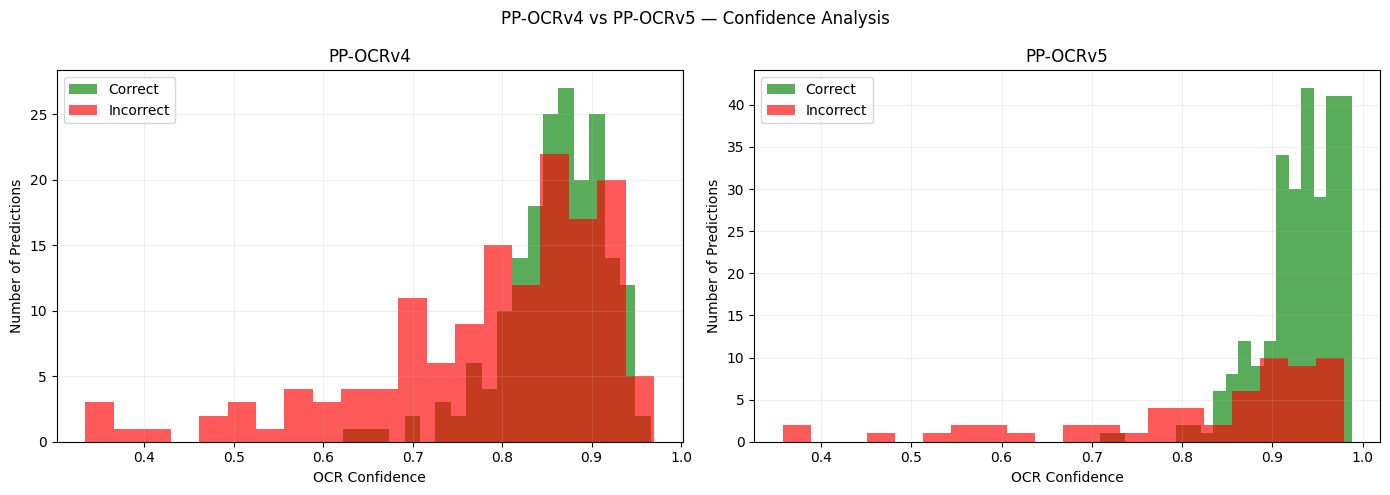


High-confidence incorrect predictions (>= 90%):
Model
PP-OCRv4    27
PP-OCRv5    27
dtype: int64


,Model,Actual,Predicted,Confidence
5,PP-OCRv4,MH02BQ9628,MH02B9628,0.917664
16,PP-OCRv4,MH01CR7388,MH01CR738,0.933483
69,PP-OCRv4,MH02DW8021,MH02D8021,0.914804
78,PP-OCRv4,MH02BQ9628,MH02B9628,0.924146
108,PP-OCRv4,MH02DW8021,MH02D8021,0.913607
114,PP-OCRv4,MH02BQ9628,MH02B962,0.909168
116,PP-OCRv4,MH02CL4017,H02CL4017,0.914427
137,PP-OCRv4,HR26AZ5927,HR26A5927,0.916307
143,PP-OCRv4,TN99F2378,TN992378,0.930334
176,PP-OCRv4,MH20BY3665,MH20B3665,0.941335


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate confidence statistics
confidence_summary = (
    results_df
    .groupby(["Model", "Correct"])["Confidence"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

print("Confidence Summary:")
display(confidence_summary.round(4))

# Plot confidence distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model_name in zip(axes, ["PP-OCRv4", "PP-OCRv5"]):

    model_results = results_df[
        results_df["Model"] == model_name
    ]

    correct = model_results[
        model_results["Correct"]
    ]["Confidence"]

    incorrect = model_results[
        ~model_results["Correct"]
    ]["Confidence"]

    ax.hist(
        correct,
        bins=20,
        alpha=0.65,
        label="Correct",
        color="green"
    )

    ax.hist(
        incorrect,
        bins=20,
        alpha=0.65,
        label="Incorrect",
        color="red"
    )

    ax.set_title(model_name)
    ax.set_xlabel("OCR Confidence")
    ax.set_ylabel("Number of Predictions")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle("PP-OCRv4 vs PP-OCRv5 — Confidence Analysis")
plt.tight_layout()

plt.savefig(
    "/content/ocr_confidence_comparison.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# Identify high-confidence incorrect predictions
high_conf_errors = results_df[
    (~results_df["Correct"]) &
    (results_df["Confidence"] >= 0.90)
]

print("\nHigh-confidence incorrect predictions (>= 90%):")
print(high_conf_errors.groupby("Model").size())

display(
    high_conf_errors[
        ["Model", "Actual", "Predicted", "Confidence"]
    ].head(10)
)

In [2]:
from google.colab import files
import os
import zipfile

print("Upload the original Kaggle dataset archive.zip")

uploaded = files.upload()

for filename in uploaded:
    print("Uploaded:", filename)

    with zipfile.ZipFile(filename, "r") as zip_ref:
        zip_ref.extractall("/content/vehicle_dataset")

print("\nDataset extracted successfully!")

image_files = []

for root, dirs, filenames in os.walk("/content/vehicle_dataset"):
    for filename in filenames:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_files.append(os.path.join(root, filename))

print("Total vehicle images found:", len(image_files))
print("First image:", image_files[0] if image_files else "None")

Upload the original Kaggle dataset archive.zip


Saving archive.zip to archive.zip
Uploaded: archive.zip

Dataset extracted successfully!
Total vehicle images found: 1698
First image: /content/vehicle_dataset/video_images/video11_4650.jpg


Total vehicle images: 1698


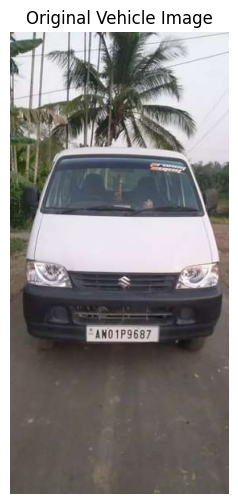

Image path: /content/vehicle_dataset/State-wise_OLX/AN/AN1.jpg
Image dimensions: (575, 272, 3)


In [3]:
import os
import cv2
import matplotlib.pyplot as plt

# Find all original vehicle images
vehicle_images = []

for root, dirs, files in os.walk("/content/vehicle_dataset"):
    for filename in files:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            vehicle_images.append(os.path.join(root, filename))

vehicle_images.sort()

print("Total vehicle images:", len(vehicle_images))

if not vehicle_images:
    raise FileNotFoundError("No vehicle images found!")

# Display the first readable vehicle image
for image_path in vehicle_images:
    image = cv2.imread(image_path)

    if image is not None:
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(10, 6))
        plt.imshow(image_rgb)
        plt.title("Original Vehicle Image")
        plt.axis("off")
        plt.show()

        print("Image path:", image_path)
        print("Image dimensions:", image.shape)
        break
else:
    raise ValueError("No readable vehicle images found.")

Total XML annotation files: 1697


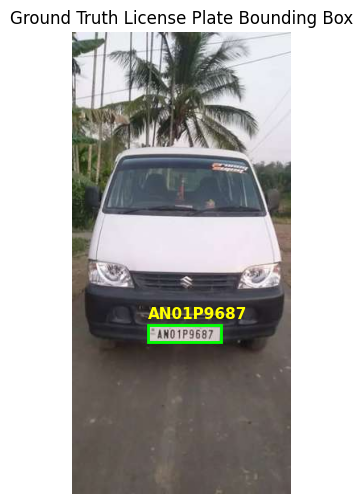

Image: /content/vehicle_dataset/State-wise_OLX/AN/AN1.jpg
Annotation: /content/vehicle_dataset/State-wise_OLX/AN/AN1.xml


In [4]:
import os
import xml.etree.ElementTree as ET
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Find XML annotation files
xml_files = []

for root, dirs, filenames in os.walk("/content/vehicle_dataset"):
    for filename in filenames:
        if filename.lower().endswith(".xml"):
            xml_files.append(os.path.join(root, filename))

xml_files.sort()

print("Total XML annotation files:", len(xml_files))

if not xml_files:
    raise FileNotFoundError("No XML annotations found!")

# Find an annotation matching an existing vehicle image
image_lookup = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in vehicle_images
}

for xml_path in xml_files:
    tree = ET.parse(xml_path)
    root = tree.getroot()

    image_name = os.path.splitext(os.path.basename(xml_path))[0]

    if image_name not in image_lookup:
        continue

    image_path = image_lookup[image_name]
    image = cv2.imread(image_path)

    if image is None:
        continue

    objects = root.findall("object")

    if not objects:
        continue

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

    for obj in objects:
        box = obj.find("bndbox")

        if box is None:
            continue

        xmin = int(float(box.findtext("xmin")))
        ymin = int(float(box.findtext("ymin")))
        xmax = int(float(box.findtext("xmax")))
        ymax = int(float(box.findtext("ymax")))

        plate_text = obj.findtext("name", "Unknown")

        rectangle = patches.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rectangle)
        ax.text(
            xmin,
            max(0, ymin - 8),
            plate_text,
            color="yellow",
            fontsize=11,
            weight="bold"
        )

    ax.set_title("Ground Truth License Plate Bounding Box")
    ax.axis("off")
    plt.show()

    print("Image:", image_path)
    print("Annotation:", xml_path)
    break

In [7]:
from google.colab import files
import os
import zipfile

print("Upload PaddleOCR_Indian_Plates_Backup.zip")

uploaded = files.upload()

for filename in uploaded:
    with zipfile.ZipFile(filename, "r") as zip_ref:
        zip_ref.extractall("/content/indian_plate_backup")

print("\nBackup extraction completed!")

backup_dir = "/content/indian_plate_backup"

required_files = {
    "PP-OCRv4 checkpoint": "models/PP-OCRv4_best_accuracy.pdparams",
    "PP-OCRv5 checkpoint": "models/PP-OCRv5_best_accuracy.pdparams",
    "PP-OCRv4 configuration": "configs/PP-OCRv4_indian_plate.yml",
    "PP-OCRv5 configuration": "configs/PP-OCRv5_indian_plate.yml",
    "Character dictionary": "indian_plate_dict.txt",
    "Validation labels": "labels/val.txt",
}

for name, relative_path in required_files.items():
    path = os.path.join(backup_dir, relative_path)
    print(f"{name}: {'FOUND' if os.path.isfile(path) else 'MISSING'}")

crop_dir = os.path.join(backup_dir, "plate_crops")

print(
    "Restored plate crops:",
    len(os.listdir(crop_dir)) if os.path.isdir(crop_dir) else 0
)

print(
    "Original vehicle dataset:",
    "FOUND" if os.path.isdir("/content/vehicle_dataset") else "MISSING"
)

Upload PaddleOCR_Indian_Plates_Backup.zip


Saving PaddleOCR_Indian_Plates_Backup.zip to PaddleOCR_Indian_Plates_Backup.zip

Backup extraction completed!
PP-OCRv4 checkpoint: FOUND
PP-OCRv5 checkpoint: FOUND
PP-OCRv4 configuration: FOUND
PP-OCRv5 configuration: FOUND
Character dictionary: FOUND
Validation labels: FOUND
Restored plate crops: 1695
Original vehicle dataset: FOUND


In [13]:
# Install with visible progress
!python -m pip install --progress-bar on paddlepaddle-gpu==3.3.0 -i https://www.paddlepaddle.org.cn/packages/stable/cu129/

Looking in indexes: https://www.paddlepaddle.org.cn/packages/stable/cu129/


In [15]:
import os
import subprocess

repo_dir = "/content/PaddleOCR"

# Clone repository only if missing
if not os.path.isdir(os.path.join(repo_dir, "ppocr")):
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/PaddlePaddle/PaddleOCR.git",
            repo_dir
        ],
        check=True
    )

print("PaddleOCR repository restored:",
      os.path.isdir(os.path.join(repo_dir, "ppocr")))

# Install repository dependencies
!python -m pip install -r /content/PaddleOCR/requirements.txt

print("\nStep 28.19 completed!")

PaddleOCR repository restored: True
Ignoring lmdb: markers 'python_version < "3.9"' don't match your environment
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 10.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 11.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 24.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [lmdb]

Step 28.19 completed!


In [16]:
import os
import sys
import yaml
import shutil
import paddle

sys.path.insert(0, "/content/PaddleOCR")

from ppocr.modeling.architectures import build_model
from ppocr.postprocess import build_post_process

backup_dir = "/content/indian_plate_backup"
config_dir = "/content/indian_plate_configs"
dict_path = "/content/PaddleOCR/ppocr/utils/indian_plate_dict.txt"

os.makedirs(config_dir, exist_ok=True)

# Restore character dictionary
shutil.copy2(
    f"{backup_dir}/indian_plate_dict.txt",
    dict_path
)

paddle.set_device("gpu")

loaded_models = {}
loaded_configs = {}
loaded_postprocess = {}

for model_name in ["PP-OCRv4", "PP-OCRv5"]:

    # Restore configuration
    config_path = f"{config_dir}/{model_name}_indian_plate.yml"

    shutil.copy2(
        f"{backup_dir}/configs/{model_name}_indian_plate.yml",
        config_path
    )

    with open(config_path, "r") as f:
        config = yaml.safe_load(f)

    config["Global"]["character_dict_path"] = dict_path

    # Prepare recognition decoder
    post_process = build_post_process(
        config["PostProcess"],
        config["Global"]
    )

    char_num = len(post_process.character)
    head_config = config["Architecture"]["Head"]

    if head_config["name"] == "MultiHead":
        head_config["out_channels_list"] = {
            "CTCLabelDecode": char_num,
            "SARLabelDecode": char_num + 2,
            "NRTRLabelDecode": char_num + 3
        }
    else:
        head_config["out_channels"] = char_num

    # Build model and load fine-tuned weights
    model = build_model(config["Architecture"])

    checkpoint_path = (
        f"{backup_dir}/models/"
        f"{model_name}_best_accuracy.pdparams"
    )

    weights = paddle.load(checkpoint_path)
    model.set_state_dict(weights)
    model.eval()

    loaded_models[model_name] = model
    loaded_configs[model_name] = config
    loaded_postprocess[model_name] = post_process

    print(f"{model_name}: loaded successfully")

print("\nModels ready:", list(loaded_models.keys()))
print("Device:", paddle.device.get_device())

Skipping import of the encryption module.


/content/PaddleOCR/ppocr/postprocess/rec_postprocess.py:1239: SyntaxWarning: invalid escape sequence '\W'
  noletter = "[\W_^\d]"
/content/PaddleOCR/ppocr/postprocess/rec_postprocess.py:1479: SyntaxWarning: invalid escape sequence '\W'
  noletter = "[\W_^\d]"
/content/PaddleOCR/ppocr/postprocess/rec_postprocess.py:1523: SyntaxWarning: invalid escape sequence '\W'
  noletter = "[\W_^\d]"
/content/PaddleOCR/ppocr/modeling/heads/rec_nrtr_head.py:371: SyntaxWarning: invalid escape sequence '\d'
  \text{MultiHead}(Q, K, V) = \text{Concat}(head_1,\dots,head_h)W^O


PP-OCRv4: loaded successfully
PP-OCRv5: loaded successfully

Models ready: ['PP-OCRv4', 'PP-OCRv5']
Device: gpu:0


In [17]:
# Install Ultralytics for license plate detection
!python -m pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 42.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 61.6 MB/s  0:00:00
  Attempting uninstall: cuda-bindings
    Found existing installation: cuda-bindings 12.9.5
    Uninstalling cuda-bindings-12.9.5:
      Successfully uninstalled cuda-bindings-12.9.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cuda-python 12.9.4 requires cuda-bindings~=12.9.4, but you have cuda-bindings 13.4.4 which is incompatible.


In [26]:
import os
import glob
import xml.etree.ElementTree as ET

dataset_dir = "/content/vehicle_dataset"

xml_files = sorted(
    glob.glob(dataset_dir + "/**/*.xml", recursive=True)
)

image_files = sorted(
    glob.glob(dataset_dir + "/**/*.jpg", recursive=True)
    + glob.glob(dataset_dir + "/**/*.jpeg", recursive=True)
    + glob.glob(dataset_dir + "/**/*.png", recursive=True)
)

print("Images found:", len(image_files))
print("XML annotations found:", len(xml_files))

if xml_files:
    root = ET.parse(xml_files[0]).getroot()

    print("\nSample XML:", xml_files[0])
    print("Objects:", len(root.findall("object")))

    for obj in root.findall("object")[:3]:
        name = obj.findtext("name")
        bbox = obj.find("bndbox")

        if bbox is not None:
            coordinates = {
                tag: bbox.findtext(tag)
                for tag in ["xmin", "ymin", "xmax", "ymax"]
            }

            print("Plate text:", name)
            print("Bounding box:", coordinates)

Images found: 1697
XML annotations found: 1697

Sample XML: /content/vehicle_dataset/State-wise_OLX/AN/AN1.xml
Objects: 1
Plate text: AN01P9687
Bounding box: {'xmin': '94', 'ymin': '364', 'xmax': '185', 'ymax': '385'}


In [27]:
import os
import glob
import random
import shutil
import yaml
import xml.etree.ElementTree as ET

source_dir = "/content/vehicle_dataset"
output_dir = "/content/yolo_plate_dataset"

random.seed(42)

xml_files = sorted(
    glob.glob(source_dir + "/**/*.xml", recursive=True)
)

# Match images to XML files using their relative paths
samples = []

for xml_path in xml_files:
    image_path = None

    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
        candidate = os.path.splitext(xml_path)[0] + ext

        if os.path.isfile(candidate):
            image_path = candidate
            break

    if image_path:
        samples.append((image_path, xml_path))

random.shuffle(samples)

split_index = int(len(samples) * 0.8)

splits = {
    "train": samples[:split_index],
    "val": samples[split_index:]
}

total_boxes = 0

for split_name, items in splits.items():

    image_out = f"{output_dir}/images/{split_name}"
    label_out = f"{output_dir}/labels/{split_name}"

    os.makedirs(image_out, exist_ok=True)
    os.makedirs(label_out, exist_ok=True)

    for index, (image_path, xml_path) in enumerate(items):

        root = ET.parse(xml_path).getroot()

        size = root.find("size")

        width = int(size.findtext("width", "0"))
        height = int(size.findtext("height", "0"))

        if width <= 0 or height <= 0:
            continue

        filename = f"{split_name}_{index:05d}"

        extension = os.path.splitext(image_path)[1].lower()

        shutil.copy2(
            image_path,
            f"{image_out}/{filename}{extension}"
        )

        labels = []

        for obj in root.findall("object"):

            bbox = obj.find("bndbox")

            if bbox is None:
                continue

            xmin = float(bbox.findtext("xmin"))
            ymin = float(bbox.findtext("ymin"))
            xmax = float(bbox.findtext("xmax"))
            ymax = float(bbox.findtext("ymax"))

            xmin = max(0, min(xmin, width))
            xmax = max(0, min(xmax, width))
            ymin = max(0, min(ymin, height))
            ymax = max(0, min(ymax, height))

            if xmax <= xmin or ymax <= ymin:
                continue

            x_center = ((xmin + xmax) / 2) / width
            y_center = ((ymin + ymax) / 2) / height

            box_width = (xmax - xmin) / width
            box_height = (ymax - ymin) / height

            labels.append(
                f"0 {x_center:.6f} {y_center:.6f} "
                f"{box_width:.6f} {box_height:.6f}"
            )

        with open(
            f"{label_out}/{filename}.txt", "w"
        ) as f:
            f.write("\n".join(labels))

        total_boxes += len(labels)

config = {
    "path": output_dir,
    "train": "images/train",
    "val": "images/val",
    "names": {0: "license_plate"}
}

config_path = f"{output_dir}/data.yaml"

with open(config_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Training images:", len(splits["train"]))
print("Validation images:", len(splits["val"]))
print("Total license plate boxes:", total_boxes)
print("YOLO configuration:", config_path)

Training images: 1356
Validation images: 340
Total license plate boxes: 1696
YOLO configuration: /content/yolo_plate_dataset/data.yaml


## Detector training (optional when checkpoint exists)
The detector was trained separately from the OCR models. The original run completed 13 epochs before interruption and saved `best.pt`; the subsequent detection outputs were produced using that checkpoint. Re-training can produce different results.

In [ ]:
# Optional: train detector ONLY if the checkpoint is not already available.
# Training is separate from PP-OCRv4/v5 recognition fine-tuning.
import os, subprocess
checkpoint = "/content/license_plate_detection/yolo11n_indian_plates/weights/best.pt"
if not os.path.isfile(checkpoint):
    env = os.environ.copy()
    env["LD_PRELOAD"] = "/usr/lib/x86_64-linux-gnu/libnccl.so.2"
    command = ["yolo", "detect", "train", "model=yolo11n.pt",
               "data=/content/yolo_plate_dataset/data.yaml", "epochs=20",
               "imgsz=640", "batch=16", "device=0", "workers=2",
               "project=/content/license_plate_detection",
               "name=yolo11n_indian_plates", "exist_ok=True"]
    subprocess.run(command, env=env, check=True)
print("Detector checkpoint available:", os.path.isfile(checkpoint))

In [31]:
import os
import pandas as pd

training_dir = "/content/license_plate_detection/yolo11n_indian_plates"
results_path = f"{training_dir}/results.csv"
weights_dir = f"{training_dir}/weights"

if os.path.isfile(results_path):
    df = pd.read_csv(results_path)
    df.columns = df.columns.str.strip()

    print("Completed epochs:", len(df))

    columns = [
        col for col in df.columns
        if col == "epoch" or "mAP50" in col
    ]

    print("\nLatest training results:")
    print(df[columns].tail(5).to_string(index=False))
else:
    print("No training results found.")

print("\nSaved checkpoints:")

for filename in ["best.pt", "last.pt"]:
    path = os.path.join(weights_dir, filename)

    if os.path.isfile(path):
        size = os.path.getsize(path) / (1024 * 1024)
        print(f"{filename}: Available ({size:.2f} MB)")
    else:
        print(f"{filename}: Not available")

Completed epochs: 13

Latest training results:
 epoch  metrics/mAP50(B)  metrics/mAP50-95(B)
     9           0.99076              0.80194
    10           0.99393              0.81462
    11           0.99448              0.79531
    12           0.99435              0.80315
    13           0.99408              0.81706

Saved checkpoints:
best.pt: Available (25.34 MB)
last.pt: Available (25.34 MB)


Testing image: /content/vehicle_dataset/State-wise_OLX/AN/AN1.jpg
Exit code: 0
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs

image 1/1 /content/vehicle_dataset/State-wise_OLX/AN/AN1.jpg: 640x320 1 license_plate, 8.9ms
Speed: 37.2ms preprocess, 8.9ms inference, 19.5ms postprocess per image at shape (1, 3, 640, 320)
Results saved to /content/license_plate_detection/sample_prediction
💡 Learn more at https://docs.ultralytics.com/modes/predict




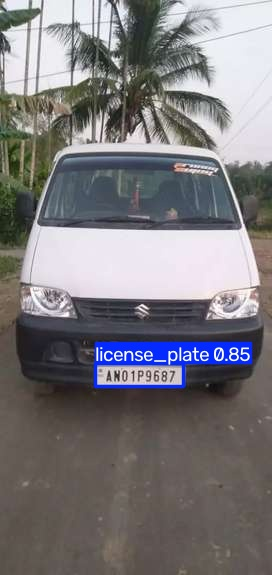

In [32]:
import os
import glob
import subprocess

model_path = (
    "/content/license_plate_detection/"
    "yolo11n_indian_plates/weights/best.pt"
)

images = sorted(
    glob.glob("/content/vehicle_dataset/**/*.jpg", recursive=True)
)

assert os.path.isfile(model_path), "Detector checkpoint missing"
assert images, "Vehicle images missing"

sample_image = images[0]

print("Testing image:", sample_image)

env = os.environ.copy()
env["LD_PRELOAD"] = "/usr/lib/x86_64-linux-gnu/libnccl.so.2"

command = [
    "yolo",
    "detect",
    "predict",
    f"model={model_path}",
    f"source={sample_image}",
    "imgsz=640",
    "conf=0.25",
    "device=0",
    "save=True",
    "project=/content/license_plate_detection",
    "name=sample_prediction",
    "exist_ok=True"
]

result = subprocess.run(
    command,
    env=env,
    capture_output=True,
    text=True,
    timeout=120
)

print("Exit code:", result.returncode)
print(result.stdout[-2500:])
print(result.stderr[-1500:])

if result.returncode == 0:
    from IPython.display import display, Image

    output_images = glob.glob(
        "/content/license_plate_detection/sample_prediction/*"
    )

    for path in output_images:
        if path.lower().endswith((".jpg", ".jpeg", ".png")):
            display(Image(filename=path))
            break

In [33]:
import os
import cv2
import numpy as np
import subprocess
from PIL import Image
from IPython.display import display

model_path = (
    "/content/license_plate_detection/"
    "yolo11n_indian_plates/weights/best.pt"
)

# Reuse the full vehicle image from the previous step
print("Vehicle image:", sample_image)

# Run YOLO in a separate process to avoid the NCCL conflict
script = """
import sys
from ultralytics import YOLO

model = YOLO(sys.argv[1])
results = model.predict(
    source=sys.argv[2],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

boxes = results[0].boxes

if len(boxes) == 0:
    print("NO_DETECTION")
else:
    best = boxes.conf.argmax().item()
    box = boxes.xyxy[best].cpu().numpy()
    confidence = boxes.conf[best].item()

    print(
        "DETECTION",
        *[round(float(x), 2) for x in box],
        round(confidence, 4)
    )
"""

env = os.environ.copy()
env["LD_PRELOAD"] = "/usr/lib/x86_64-linux-gnu/libnccl.so.2"

result = subprocess.run(
    ["python", "-c", script, model_path, sample_image],
    env=env,
    capture_output=True,
    text=True,
    timeout=120
)

if result.returncode != 0:
    raise RuntimeError(result.stderr[-2000:])

detection_line = next(
    (line for line in result.stdout.splitlines()
     if line.startswith("DETECTION ")),
    None
)

if detection_line is None:
    raise RuntimeError(
        "No plate detected. Output:\n" + result.stdout
    )

values = list(map(float, detection_line.split()[1:]))

x1, y1, x2, y2, detection_confidence = values

image = cv2.imread(sample_image)
h, w = image.shape[:2]

# Add a small margin around the detected plate
margin = 4

x1 = max(0, int(x1) - margin)
y1 = max(0, int(y1) - margin)
x2 = min(w, int(x2) + margin)
y2 = min(h, int(y2) + margin)

plate_crop = image[y1:y2, x1:x2]

assert plate_crop.size > 0, "Detected crop is empty"

crop_path = "/content/detected_license_plate.jpg"
cv2.imwrite(crop_path, plate_crop)

print(f"Detection confidence: {detection_confidence:.2%}")
print("Crop saved:", crop_path)
print("Crop dimensions:", plate_crop.shape)

display(Image.fromarray(
    cv2.cvtColor(plate_crop, cv2.COLOR_BGR2RGB)
))

Vehicle image: /content/vehicle_dataset/State-wise_OLX/AN/AN1.jpg
Detection confidence: 84.74%
Crop saved: /content/detected_license_plate.jpg
Crop dimensions: (31, 96, 3)


In [34]:
import os
import sys
import cv2
import numpy as np
import paddle

sys.path.insert(0, "/content/PaddleOCR")

from ppocr.data.imaug import create_operators, transform

crop_path = "/content/detected_license_plate.jpg"

assert os.path.isfile(crop_path), "Detected plate crop missing"

def recognize_plate(model_name, image_path):
    model = loaded_models[model_name]
    config = loaded_configs[model_name]
    postprocess = loaded_postprocess[model_name]

    # Use evaluation preprocessing from the model configuration
    transforms = []

    for operation in config["Eval"]["dataset"]["transforms"]:
        operation_name = list(operation.keys())[0]

        if operation_name in ["KeepKeys", "LabelEncode", "MultiLabelEncode"]:
            continue

        transforms.append(operation)

    transforms.append({"KeepKeys": {"keep_keys": ["image"]}})

    operators = create_operators(
        transforms,
        config["Global"]
    )

    with open(image_path, "rb") as f:
        image_bytes = f.read()

    data = transform(
        {"image": image_bytes},
        operators
    )

    if data is None:
        raise ValueError("Image preprocessing failed")

    image = data[0]

    if image.ndim == 3:
        image = np.expand_dims(image, axis=0)

    image_tensor = paddle.to_tensor(image)

    with paddle.no_grad():
        predictions = model(image_tensor)

    decoded = postprocess(predictions)

    # Extract recognition text and confidence
    text, confidence = decoded[0]

    return text, float(confidence)


print("YOLO detection confidence:", f"{detection_confidence:.2%}")
print("-" * 55)

for model_name in ["PP-OCRv4", "PP-OCRv5"]:
    text, confidence = recognize_plate(model_name, crop_path)

    print(f"{model_name}")
    print("Predicted plate:", text)
    print("OCR confidence:", f"{confidence:.2%}")
    print("-" * 55)

YOLO detection confidence: 84.74%
-------------------------------------------------------
PP-OCRv4
Predicted plate: AN01P9687
OCR confidence: 83.37%
-------------------------------------------------------
PP-OCRv5
Predicted plate: AN01P9687
OCR confidence: 97.12%
-------------------------------------------------------


In [35]:
import os
import xml.etree.ElementTree as ET

xml_path = os.path.splitext(sample_image)[0] + ".xml"

assert os.path.isfile(xml_path), f"XML not found: {xml_path}"

root = ET.parse(xml_path).getroot()

ground_truths = []

for obj in root.findall("object"):
    plate_text = obj.findtext("name", "").strip().upper()
    if plate_text:
        ground_truths.append(plate_text)

v4_text, v4_conf = recognize_plate(
    "PP-OCRv4", crop_path
)

v5_text, v5_conf = recognize_plate(
    "PP-OCRv5", crop_path
)

print("Ground truth:", ground_truths)
print()
print("PP-OCRv4:", v4_text)
print("Correct:", v4_text in ground_truths)
print("Confidence:", f"{v4_conf:.2%}")
print()
print("PP-OCRv5:", v5_text)
print("Correct:", v5_text in ground_truths)
print("Confidence:", f"{v5_conf:.2%}")

Ground truth: ['AN01P9687']

PP-OCRv4: AN01P9687
Correct: True
Confidence: 83.37%

PP-OCRv5: AN01P9687
Correct: True
Confidence: 97.12%


In [36]:
import os
import glob
import json
import subprocess
import pandas as pd
import xml.etree.ElementTree as ET

val_images = sorted(
    glob.glob("/content/yolo_plate_dataset/images/val/*")
)[:20]

model_path = (
    "/content/license_plate_detection/"
    "yolo11n_indian_plates/weights/best.pt"
)

assert val_images, "No validation images found"
assert os.path.isfile(model_path), "YOLO checkpoint missing"

output_dir = "/content/batch_detected_plates"
os.makedirs(output_dir, exist_ok=True)

# Run YOLO in a separate Python process
script = r"""
import sys
import json
import cv2
from ultralytics import YOLO

model = YOLO(sys.argv[1])
image_paths = json.loads(sys.argv[2])
output_dir = sys.argv[3]

results = model.predict(
    source=image_paths,
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

records = []

for index, result in enumerate(results):
    image_path = image_paths[index]
    image = cv2.imread(image_path)

    record = {
        "image": image_path,
        "crop": "",
        "detection_confidence": 0.0
    }

    if image is not None and len(result.boxes) > 0:
        best = int(result.boxes.conf.argmax().item())

        box = result.boxes.xyxy[best].cpu().numpy()
        confidence = float(result.boxes.conf[best].item())

        h, w = image.shape[:2]

        x1, y1, x2, y2 = [int(x) for x in box]

        x1 = max(0, x1 - 4)
        y1 = max(0, y1 - 4)
        x2 = min(w, x2 + 4)
        y2 = min(h, y2 + 4)

        crop = image[y1:y2, x1:x2]

        if crop.size > 0:
            crop_path = f"{output_dir}/plate_{index:03d}.jpg"
            cv2.imwrite(crop_path, crop)

            record["crop"] = crop_path
            record["detection_confidence"] = confidence

    records.append(record)

print("RESULT_JSON=" + json.dumps(records))
"""

env = os.environ.copy()
env["LD_PRELOAD"] = "/usr/lib/x86_64-linux-gnu/libnccl.so.2"

result = subprocess.run(
    [
        "python", "-c", script,
        model_path,
        json.dumps(val_images),
        output_dir
    ],
    env=env,
    capture_output=True,
    text=True,
    timeout=180
)

if result.returncode != 0:
    raise RuntimeError(result.stderr[-3000:])

result_line = next(
    line for line in result.stdout.splitlines()
    if line.startswith("RESULT_JSON=")
)

detections = json.loads(result_line.split("=", 1)[1])

rows = []

for item in detections:
    image_path = item["image"]
    crop_path = item["crop"]

    # YOLO dataset labels are class IDs, not plate text.
    # Match the original image to its XML using the YOLO
    # conversion's train/validation index mapping.
    # Ground truth remains unavailable until that mapping
    # is reconstructed, so do not invent correctness values.

    row = {
        "image": os.path.basename(image_path),
        "detected": bool(crop_path),
        "detection_confidence": item["detection_confidence"],
        "v4_prediction": "",
        "v4_confidence": None,
        "v5_prediction": "",
        "v5_confidence": None
    }

    if crop_path:
        v4_text, v4_conf = recognize_plate("PP-OCRv4", crop_path)
        v5_text, v5_conf = recognize_plate("PP-OCRv5", crop_path)

        row["v4_prediction"] = v4_text
        row["v4_confidence"] = v4_conf
        row["v5_prediction"] = v5_text
        row["v5_confidence"] = v5_conf

    rows.append(row)

batch_df = pd.DataFrame(rows)

csv_path = "/content/full_image_ocr_comparison.csv"
batch_df.to_csv(csv_path, index=False)

print("\nImages tested:", len(batch_df))
print("Plates detected:", int(batch_df["detected"].sum()))
print("Detection rate:", f"{batch_df['detected'].mean():.2%}")
print("\nResults:")
print(batch_df.to_string(index=False))
print("\nSaved:", csv_path)


Images tested: 20
Plates detected: 20
Detection rate: 100.00%

Results:
         image  detected  detection_confidence v4_prediction  v4_confidence v5_prediction  v5_confidence
 val_00000.jpg      True              0.744235    CG07BR3255       0.829121    CG07BR3255       0.978099
 val_00001.jpg      True              0.816640    CH01BL3528       0.870380    CH01BL3528       0.977211
val_00002.jpeg      True              0.826657     MH20B4465       0.870231    MH20BY4465       0.881247
 val_00003.jpg      True              0.859686    MH02DS9365       0.910452    MH02DS9365       0.944604
 val_00004.jpg      True              0.857544     MH47Y1124       0.792029     MH47Y1124       0.899499
 val_00005.jpg      True              0.709442        ML5047       0.481126       MH45475       0.440172
 val_00006.jpg      True              0.863871     CH01A9090       0.895387    CH01AX9090       0.960987
 val_00007.jpg      True              0.871810    PB08C03690       0.953884    PB08C036

In [37]:
import os
import glob
import random
import pandas as pd
import xml.etree.ElementTree as ET

source_dir = "/content/vehicle_dataset"

xml_files = sorted(
    glob.glob(source_dir + "/**/*.xml", recursive=True)
)

samples = []

for xml_path in xml_files:
    image_path = None

    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
        candidate = os.path.splitext(xml_path)[0] + ext

        if os.path.isfile(candidate):
            image_path = candidate
            break

    if image_path:
        samples.append((image_path, xml_path))

random.Random(42).shuffle(samples)

split_index = int(len(samples) * 0.8)
validation_samples = samples[split_index:]

# Reconstruct mapping from YOLO validation filenames
ground_truth_map = {}

for index, (image_path, xml_path) in enumerate(validation_samples):
    ext = os.path.splitext(image_path)[1].lower()
    filename = f"val_{index:05d}{ext}"

    root = ET.parse(xml_path).getroot()

    labels = [
        obj.findtext("name", "").strip().upper()
        for obj in root.findall("object")
    ]

    ground_truth_map[filename] = [
        label for label in labels if label
    ]

# Add ground truth and exact-match correctness
batch_df["ground_truth"] = batch_df["image"].map(
    lambda name: ground_truth_map.get(name, [])
)

batch_df["v4_correct"] = batch_df.apply(
    lambda row: row["v4_prediction"] in row["ground_truth"],
    axis=1
)

batch_df["v5_correct"] = batch_df.apply(
    lambda row: row["v5_prediction"] in row["ground_truth"],
    axis=1
)

print("Images evaluated:", len(batch_df))
print("Detection rate:", f"{batch_df['detected'].mean():.2%}")
print("PP-OCRv4 exact match:", f"{batch_df['v4_correct'].mean():.2%}")
print("PP-OCRv5 exact match:", f"{batch_df['v5_correct'].mean():.2%}")

print("\nDetailed comparison:")
print(
    batch_df[
        [
            "image",
            "ground_truth",
            "v4_prediction",
            "v4_correct",
            "v5_prediction",
            "v5_correct"
        ]
    ].to_string(index=False)
)

csv_path = "/content/full_image_ocr_comparison.csv"
batch_df.to_csv(csv_path, index=False)

print("\nUpdated CSV:", csv_path)

Images evaluated: 20
Detection rate: 100.00%
PP-OCRv4 exact match: 45.00%
PP-OCRv5 exact match: 90.00%

Detailed comparison:
         image ground_truth v4_prediction  v4_correct v5_prediction  v5_correct
 val_00000.jpg [CG07BR3255]    CG07BR3255        True    CG07BR3255        True
 val_00001.jpg [CH01BL3528]    CH01BL3528        True    CH01BL3528        True
val_00002.jpeg [MH20BY4465]     MH20B4465       False    MH20BY4465        True
 val_00003.jpg [MH02DS9365]    MH02DS9365        True    MH02DS9365        True
 val_00004.jpg  [MH47Y1124]     MH47Y1124        True     MH47Y1124        True
 val_00005.jpg [MH04JL5547]        ML5047       False       MH45475       False
 val_00006.jpg [CH01AX9090]     CH01A9090       False    CH01AX9090        True
 val_00007.jpg [PB08C03690]    PB08C03690        True    PB08C03690        True
val_00008.jpeg [MP09CP9052]    MHP09CP902       False    MP09CP9052        True
 val_00009.jpg  [ML05G3474]     ML05G3474        True     ML05G3474        

In [38]:
import os
import shutil
import pandas as pd
from google.colab import files

submission_dir = "/content/PaddleOCR_Final_Submission"
os.makedirs(submission_dir, exist_ok=True)

# 1. Save full-image inference results
batch_df.to_csv(
    f"{submission_dir}/full_image_ocr_comparison.csv",
    index=False
)

# 2. Save summary metrics
summary = pd.DataFrame([
    {
        "model": "PP-OCRv4",
        "ocr_validation_images": 330,
        "ocr_validation_accuracy": 0.5667,
        "normalized_edit_similarity": 0.9247,
        "pipeline_sample_images": 20,
        "pipeline_correct": 9,
        "pipeline_accuracy": 0.45
    },
    {
        "model": "PP-OCRv5",
        "ocr_validation_images": 330,
        "ocr_validation_accuracy": 0.8212,
        "normalized_edit_similarity": 0.9655,
        "pipeline_sample_images": 20,
        "pipeline_correct": 18,
        "pipeline_accuracy": 0.90
    }
])

summary.to_csv(
    f"{submission_dir}/model_comparison_summary.csv",
    index=False
)

# 3. Copy detector checkpoint
detector = (
    "/content/license_plate_detection/"
    "yolo11n_indian_plates/weights/best.pt"
)

if os.path.isfile(detector):
    shutil.copy2(
        detector,
        f"{submission_dir}/license_plate_detector_best.pt"
    )

# 4. Copy OCR checkpoints from backup
backup_dir = "/content/indian_plate_backup"

for model in ["PP-OCRv4", "PP-OCRv5"]:
    source = f"{backup_dir}/models/{model}_best_accuracy.pdparams"

    if os.path.isfile(source):
        shutil.copy2(
            source,
            f"{submission_dir}/{model}_best_accuracy.pdparams"
        )

# 5. Save a short results report
report = """# Indian License Plate Recognition — Final Results

## Models
- PP-OCRv4 fine-tuned recognition model
- PP-OCRv5 fine-tuned recognition model
- YOLO11n license plate detector

## OCR Validation (330 images)
- PP-OCRv4 exact-match accuracy: 56.67%
- PP-OCRv5 exact-match accuracy: 82.12%
- PP-OCRv4 normalized edit similarity: 92.47%
- PP-OCRv5 normalized edit similarity: 96.55%

## Full-Image Pipeline Demonstration (20 images)
- License plates detected: 20/20
- PP-OCRv4 exact matches: 9/20 (45%)
- PP-OCRv5 exact matches: 18/20 (90%)

## Conclusion
PP-OCRv5 outperformed PP-OCRv4 in both the 330-image
OCR validation and the 20-image full-image pipeline sample.

## Evaluation Limitation
The 20-image pipeline sample is not an independent
end-to-end benchmark because the detector and OCR
datasets were split independently.
"""

with open(f"{submission_dir}/RESULTS.md", "w") as f:
    f.write(report)

# 6. Create downloadable ZIP
zip_path = shutil.make_archive(
    "/content/PaddleOCR_Final_Submission",
    "zip",
    submission_dir
)

print("Submission ZIP created:", zip_path)
print("Files included:", os.listdir(submission_dir))

files.download(zip_path)

Submission ZIP created: /content/PaddleOCR_Final_Submission.zip
Files included: ['full_image_ocr_comparison.csv', 'license_plate_detector_best.pt', 'PP-OCRv5_best_accuracy.pdparams', 'RESULTS.md', 'model_comparison_summary.csv', 'PP-OCRv4_best_accuracy.pdparams']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Results and limitations

| Evaluation | PP-OCRv4 | PP-OCRv5 |
|---|---:|---:|
| 330 cropped-plate validation images: exact match | 56.67% | **82.12%** |
| Normalized edit similarity | 92.47% | **96.55%** |
| 20 full-image pipeline samples: exact match | 45% (9/20) | **90% (18/20)** |

The detector found a plate in all 20 tested images. The 20-image set is a **pipeline demonstration**, not an independent end-to-end benchmark: detector and OCR splits were created independently, and some evaluation examples may overlap OCR training. The reported 100% detection rate applies **only to this 20-image sample**. Predictions and confidence scores are saved by the notebook in CSV form. The OCR checkpoints are training `.pdparams` files, not exported Paddle inference-model artifacts.